In [1]:
from google.colab import files

uploaded = files.upload()

Saving insurance.csv to insurance (1).csv


In [2]:
import pandas as pd

df = pd.read_csv("insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nData types and missing values:")
df.info()

print("\nSummary statistics:")
df.describe()

Dataset shape: (1338, 7)

Column names:
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Summary statistics:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
from sklearn.model_selection import train_test_split

# 1. Separate the features (X) and target variable (y)
# We'll use one-hot encoding on categorical variables ('sex', 'smoker', 'region')
X = pd.get_dummies(df.drop(columns=['charges']), drop_first=True)
y = df['charges']

# 2. Perform the train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nFeatures (X) columns after encoding:", list(X.columns))

Training rows: 1070
Testing rows: 268

Features (X) columns after encoding: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [20]:
from pathlib import Path
import warnings
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

SEED = 42
TEST_SIZE = 0.20
N_SPLITS = 5
TARGET = "charges"
REQUIRED_COLUMNS = ["age", "sex", "bmi", "children", "smoker", "region", TARGET]

FIGURE_DIR = Path("reports/figures")
REPORT_DIR = Path("reports")
MODEL_DIR = Path("models")
for directory in (FIGURE_DIR, REPORT_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__} | NumPy: {np.__version__} | scikit-learn: {sklearn.__version__}")
print(f"Random seed: {SEED} | Test size: {TEST_SIZE:.0%} | CV folds: {N_SPLITS}")

Python: 3.13.16
pandas: 2.2.3 | NumPy: 2.1.3 | scikit-learn: 1.6.1
Random seed: 42 | Test size: 20% | CV folds: 5


In [21]:
def load_insurance_csv():
    """Find insurance.csv, or ask for an upload when running in Google Colab."""
    candidates = [Path("insurance.csv"), Path("data/insurance.csv"), Path("/content/insurance.csv")]
    for path in candidates:
        if path.exists():
            print(f"Loading dataset from: {path}")
            return pd.read_csv(path), str(path)

    try:
        from google.colab import files
        print("Upload the insurance.csv file you downloaded from Kaggle.")
        uploaded = files.upload()
    except ImportError as exc:
        raise FileNotFoundError(
            "Could not find insurance.csv. Place it at ./insurance.csv or ./data/insurance.csv."
        ) from exc

    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_names:
        raise ValueError("No CSV file was uploaded. Please upload the Kaggle insurance.csv file.")
    selected = next((name for name in csv_names if "insurance" in name.lower()), csv_names[0])
    print(f"Loading uploaded file: {selected}")
    return pd.read_csv(selected), selected


df_raw, DATA_SOURCE_NAME = load_insurance_csv()
print(f"Source file: {DATA_SOURCE_NAME}")
display(df_raw.head())

Loading dataset from: insurance.csv
Source file: insurance.csv


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [22]:
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(df_raw.columns))
if missing_columns:
    raise ValueError(
        f"The CSV is missing required columns: {missing_columns}. "
        f"Columns found: {list(df_raw.columns)}"
    )

# Restrict this experiment to the documented seven columns, in a stable order.
df = df_raw[REQUIRED_COLUMNS].copy()
rows_before = len(df)
missing_target_count = int(df[TARGET].isna().sum())
if missing_target_count:
    warnings.warn(f"Removing {missing_target_count} row(s) with missing target '{TARGET}'.")
    df = df.dropna(subset=[TARGET]).copy()

duplicate_count = int(df.duplicated().sum())
print(f"Rows in source file: {rows_before:,}")
print(f"Rows removed due to missing target: {missing_target_count:,}")
print(f"Exact duplicate rows flagged (not automatically removed): {duplicate_count:,}")
print(f"Analysis shape: {df.shape}")

print("\nMissing values by column:")
display(df.isna().sum().rename("missing_count").to_frame())
print("\nColumn types:")
df.info()
print("\nNumeric summary:")
display(df.describe().T)

# Validate target and key numerical features without silently coercing values.
df[TARGET] = pd.to_numeric(df[TARGET], errors="raise")
for col in ["age", "bmi", "children"]:
    df[col] = pd.to_numeric(df[col], errors="raise")
if df.empty:
    raise ValueError("No rows remain after checking the target column.")
if not np.isfinite(df[TARGET].to_numpy(dtype=float)).all():
    raise ValueError("The target contains non-finite values; investigate the source CSV.")

Rows in source file: 1,338
Rows removed due to missing target: 0
Exact duplicate rows flagged (not automatically removed): 1
Analysis shape: (1338, 7)

Missing values by column:


,missing_count
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0



Column types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


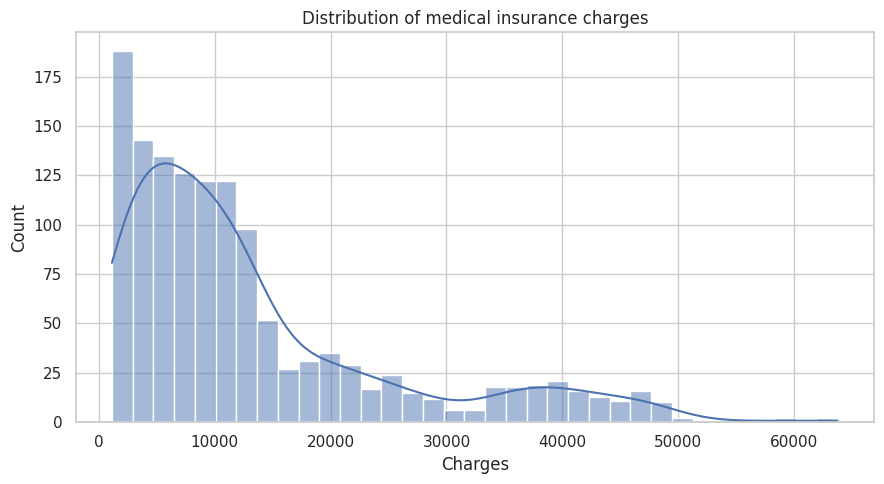

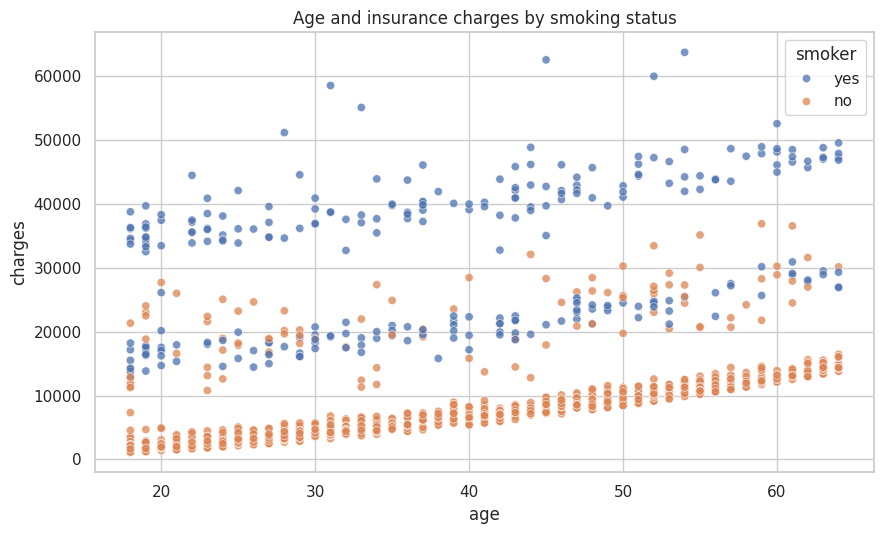

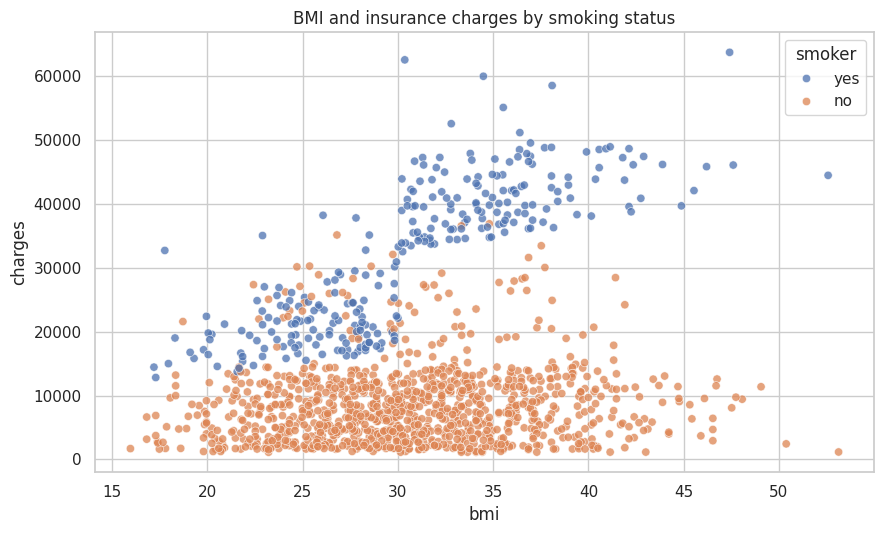

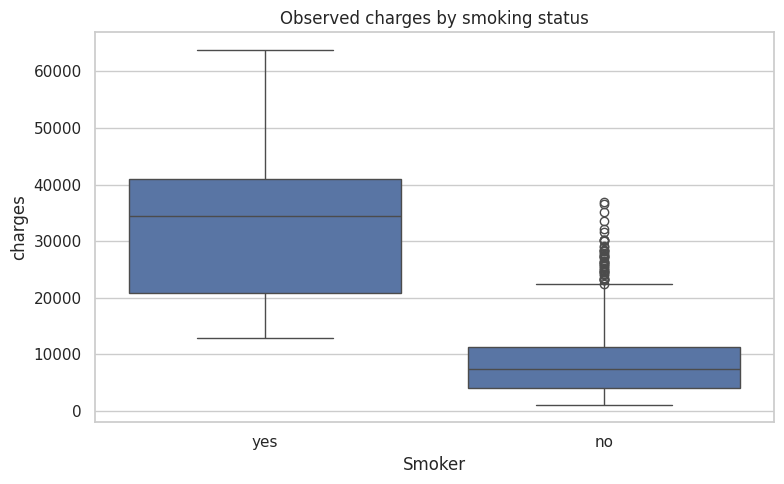

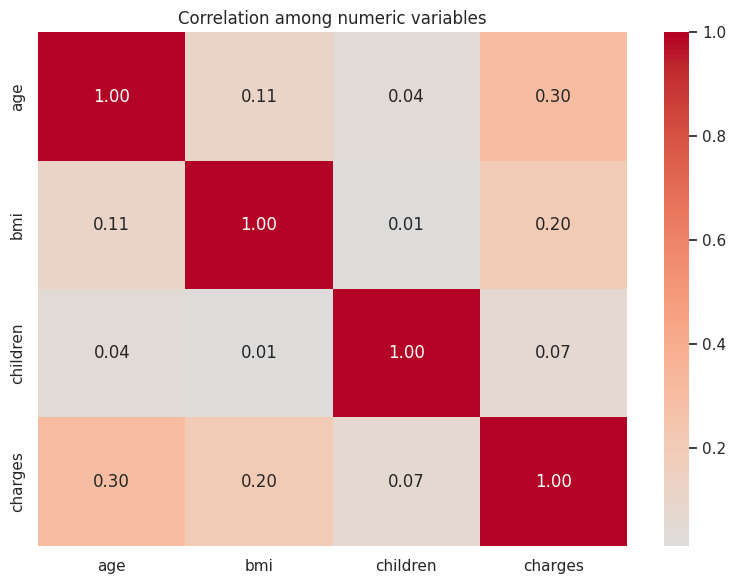

In [23]:
# 4.1 Target distribution
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x=TARGET, kde=True, bins=35, ax=ax, color=sns.color_palette()[0])
ax.set_title("Distribution of medical insurance charges")
ax.set_xlabel("Charges")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_target_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

# 4.2 Age vs charges, with smoking status shown as a group
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=df, x="age", y=TARGET, hue="smoker", alpha=0.75, ax=ax)
ax.set_title("Age and insurance charges by smoking status")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_age_vs_charges.png", dpi=160, bbox_inches="tight")
plt.show()

# 4.3 BMI vs charges
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=df, x="bmi", y=TARGET, hue="smoker", alpha=0.75, ax=ax)
ax.set_title("BMI and insurance charges by smoking status")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_bmi_vs_charges.png", dpi=160, bbox_inches="tight")
plt.show()

# 4.4 Charges across smoker groups
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="smoker", y=TARGET, ax=ax)
ax.set_title("Observed charges by smoking status")
ax.set_xlabel("Smoker")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_charges_by_smoker.png", dpi=160, bbox_inches="tight")
plt.show()

# 4.5 Numeric correlation heatmap (association, not causation)
fig, ax = plt.subplots(figsize=(8, 6))
correlation = df[["age", "bmi", "children", TARGET]].corr(numeric_only=True)
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation among numeric variables")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_numeric_correlation.png", dpi=160, bbox_inches="tight")
plt.show()

In [24]:
FEATURES = ["age", "sex", "bmi", "children", "smoker", "region"]
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

X = df[FEATURES].copy()
y = df[TARGET].astype(float).copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED
)

print(f"Training rows: {len(X_train):,} ({len(X_train)/len(df):.1%})")
print(f"Held-out test rows: {len(X_test):,} ({len(X_test)/len(df):.1%})")
print("X_train shape:", X_train.shape, "| X_test shape:", X_test.shape)

Training rows: 1,070 (80.0%)
Held-out test rows: 268 (20.0%)
X_train shape: (1070, 6) | X_test shape: (268, 6)


In [25]:
def make_preprocessor(poly_degree=None, numeric_subset=None):
    """Build preprocessing; polynomial expansion applies only to numeric columns."""
    nums = numeric_subset if numeric_subset is not None else numeric_features
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if poly_degree is not None:
        numeric_steps.append(("polynomial", PolynomialFeatures(degree=poly_degree, include_bias=False)))
    numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipeline = Pipeline(steps=numeric_steps)

    transformers = [("numeric", numeric_pipeline, nums)]
    if numeric_subset is None:
        categorical_pipeline = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ])
        transformers.append(("categorical", categorical_pipeline, categorical_features))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False,
    )


def make_regression_pipeline(model, poly_degree=None, numeric_subset=None):
    """Preprocess then fit a regression estimator."""
    return Pipeline(steps=[
        ("preprocess", make_preprocessor(poly_degree=poly_degree, numeric_subset=numeric_subset)),
        ("regressor", model),
    ])

In [26]:
models = {
    "Dummy baseline (mean)": DummyRegressor(strategy="mean"),
    "Simple linear (age only)": make_regression_pipeline(
        LinearRegression(), numeric_subset=["age"]
    ),
    "Multiple linear regression": make_regression_pipeline(LinearRegression()),
    "Polynomial regression (degree 2)": make_regression_pipeline(
        LinearRegression(), poly_degree=2
    ),
    "Polynomial regression (degree 3)": make_regression_pipeline(
        LinearRegression(), poly_degree=3
    ),
    "Ridge + polynomial degree 2": make_regression_pipeline(
        Ridge(alpha=1.0), poly_degree=2
    ),
}

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_rows = []
for name, estimator in models.items():
    scores = cross_val_score(
        estimator,
        X_train,
        y_train,
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1,
    )
    fold_mae = -scores
    cv_rows.append({
        "model": name,
        "cv_mae_mean": float(fold_mae.mean()),
        "cv_mae_std": float(fold_mae.std(ddof=1)),
        "cv_folds": N_SPLITS,
    })

cv_results = pd.DataFrame(cv_rows).sort_values("cv_mae_mean").reset_index(drop=True)
non_dummy_cv = cv_results[cv_results["model"] != "Dummy baseline (mean)"]
best_model_name = str(non_dummy_cv.iloc[0]["model"])
print("Cross-validation MAE on training data (lower is better):")
display(cv_results.style.format({"cv_mae_mean": "{:,.2f}", "cv_mae_std": "{:,.2f}"}))
print(f"Selected candidate by training CV MAE: {best_model_name}")

Cross-validation MAE on training data (lower is better):


,model,cv_mae_mean,cv_mae_std,cv_folds
0,Multiple linear regression,"4,234.98",277.28,5
1,Ridge + polynomial degree 2,"4,319.14",266.75,5
2,Polynomial regression (degree 3),"4,325.23",298.07,5
3,Polynomial regression (degree 2),"4,326.94",263.06,5
4,Dummy baseline (mean),"9,007.09",326.06,5
5,Simple linear (age only),"9,048.28",222.00,5


Selected candidate by training CV MAE: Multiple linear regression


In [27]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
    }

fitted_models = {}
evaluation_rows = []
predictions = {}
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    fitted_models[name] = estimator
    train_pred = estimator.predict(X_train)
    test_pred = estimator.predict(X_test)
    predictions[name] = test_pred
    train_metrics = regression_metrics(y_train, train_pred)
    test_metrics = regression_metrics(y_test, test_pred)
    cv_row = cv_results.loc[cv_results["model"] == name].iloc[0]
    evaluation_rows.append({
        "model": name,
        "cv_mae_mean": float(cv_row["cv_mae_mean"]),
        "cv_mae_std": float(cv_row["cv_mae_std"]),
        "train_mae": train_metrics["MAE"],
        "test_mae": test_metrics["MAE"],
        "test_rmse": test_metrics["RMSE"],
        "test_r2": test_metrics["R2"],
        "train_test_mae_gap": test_metrics["MAE"] - train_metrics["MAE"],
        "selected_by_cv": name == best_model_name,
    })

results = pd.DataFrame(evaluation_rows).sort_values("cv_mae_mean").reset_index(drop=True)
results.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
cv_results.to_csv(REPORT_DIR / "cross_validation_results.csv", index=False)
print("Model comparison (candidate selection is based on training CV MAE):")
display(results.style.format({
    "cv_mae_mean": "{:,.2f}", "cv_mae_std": "{:,.2f}",
    "train_mae": "{:,.2f}", "test_mae": "{:,.2f}",
    "test_rmse": "{:,.2f}", "test_r2": "{:.3f}",
    "train_test_mae_gap": "{:,.2f}",
}))

best_model = fitted_models[best_model_name]
best_test_pred = predictions[best_model_name]
final_test_metrics = regression_metrics(y_test, best_test_pred)
print(f"\nSelected model: {best_model_name}")
print("Held-out test metrics for selected model:")
for metric, value in final_test_metrics.items():
    print(f"  {metric}: {value:,.4f}")

Model comparison (candidate selection is based on training CV MAE):


,model,cv_mae_mean,cv_mae_std,train_mae,test_mae,test_rmse,test_r2,train_test_mae_gap,selected_by_cv
0,Multiple linear regression,"4,234.98",277.28,"4,208.23","4,181.19","5,796.28",0.784,-27.04,True
1,Ridge + polynomial degree 2,"4,319.14",266.75,"4,259.02","4,248.84","5,834.18",0.781,-10.18,False
2,Polynomial regression (degree 3),"4,325.23",298.07,"4,202.40","4,199.49","5,879.68",0.777,-2.91,False
3,Polynomial regression (degree 2),"4,326.94",263.06,"4,264.44","4,254.27","5,841.28",0.780,-10.17,False
4,Dummy baseline (mean),"9,007.09",326.06,"9,000.56","9,593.34","12,465.61",-0.001,592.78,False
5,Simple linear (age only),"9,048.28",222.00,"9,042.42","9,173.26","11,661.22",0.124,130.84,False



Selected model: Multiple linear regression
Held-out test metrics for selected model:
  MAE: 4,181.1945
  RMSE: 5,796.2847
  R2: 0.7836


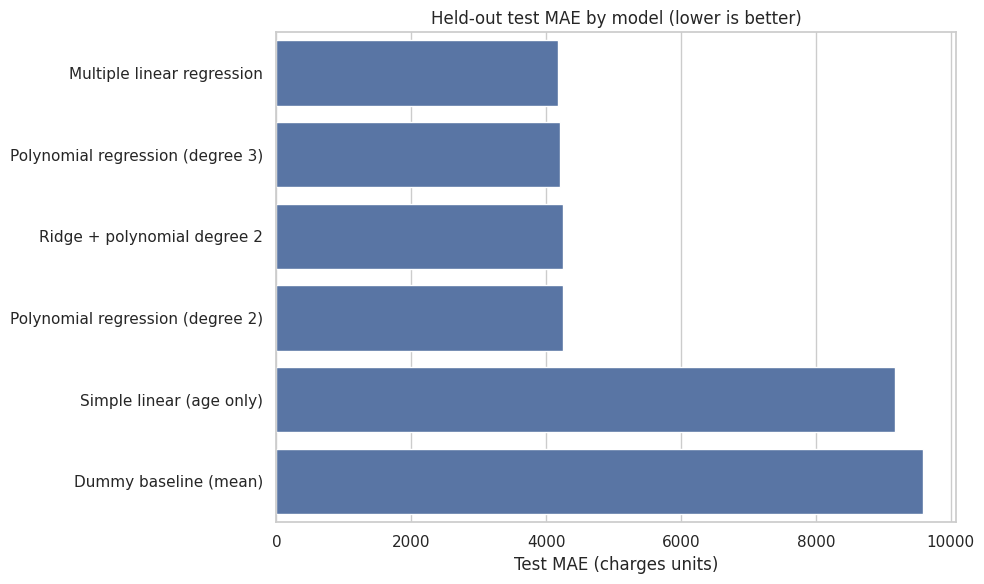

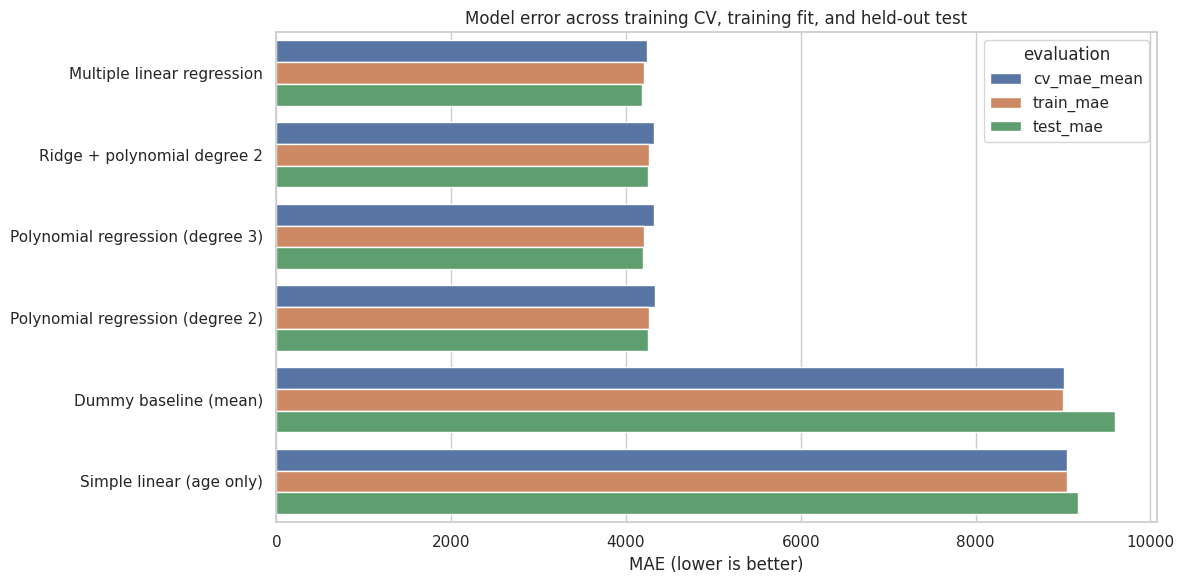

In [28]:
# Holdout test MAE comparison
plot_results = results.sort_values("test_mae", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_results, x="test_mae", y="model", ax=ax, color=sns.color_palette()[0])
ax.set_title("Held-out test MAE by model (lower is better)")
ax.set_xlabel("Test MAE (charges units)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_test_mae_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Train/CV/test MAE comparison
long_mae = results.melt(
    id_vars="model",
    value_vars=["cv_mae_mean", "train_mae", "test_mae"],
    var_name="evaluation", value_name="MAE"
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=long_mae, x="MAE", y="model", hue="evaluation", ax=ax)
ax.set_title("Model error across training CV, training fit, and held-out test")
ax.set_xlabel("MAE (lower is better)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_train_cv_test_mae.png", dpi=160, bbox_inches="tight")
plt.show()

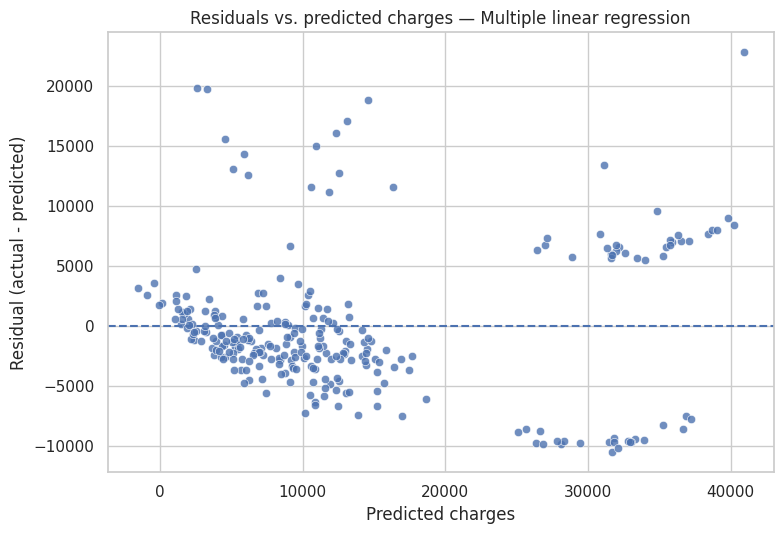

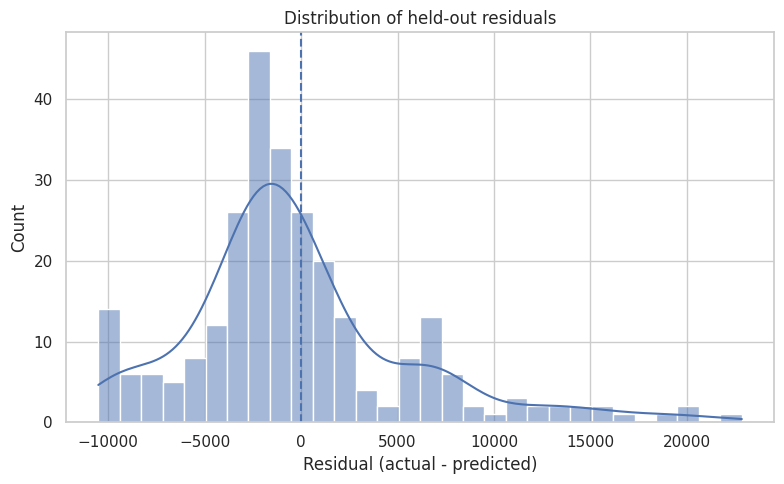

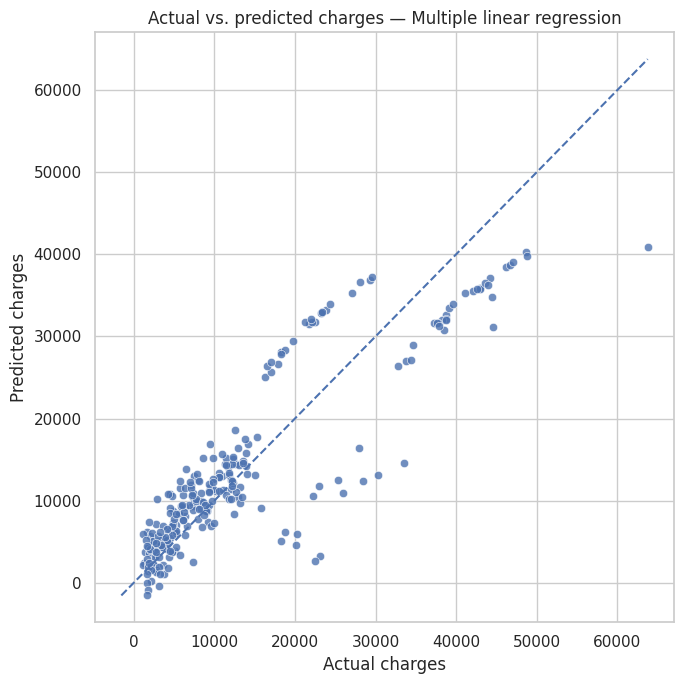

In [29]:
residuals = y_test.to_numpy() - np.asarray(best_test_pred)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=best_test_pred, y=residuals, alpha=0.8, ax=ax)
ax.axhline(0, linestyle="--", linewidth=1.5)
ax.set_title(f"Residuals vs. predicted charges — {best_model_name}")
ax.set_xlabel("Predicted charges")
ax.set_ylabel("Residual (actual - predicted)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_residuals_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(residuals, kde=True, bins=30, ax=ax, color=sns.color_palette()[0])
ax.axvline(0, linestyle="--", linewidth=1.5)
ax.set_title("Distribution of held-out residuals")
ax.set_xlabel("Residual (actual - predicted)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_residual_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

actual_vs_pred = pd.DataFrame({"actual": y_test.to_numpy(), "predicted": np.asarray(best_test_pred)})
low = min(actual_vs_pred["actual"].min(), actual_vs_pred["predicted"].min())
high = max(actual_vs_pred["actual"].max(), actual_vs_pred["predicted"].max())
fig, ax = plt.subplots(figsize=(7, 7))
sns.scatterplot(data=actual_vs_pred, x="actual", y="predicted", alpha=0.8, ax=ax)
ax.plot([low, high], [low, high], linestyle="--", linewidth=1.5)
ax.set_title(f"Actual vs. predicted charges — {best_model_name}")
ax.set_xlabel("Actual charges")
ax.set_ylabel("Predicted charges")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "10_actual_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

,feature,mae_increase_mean,mae_increase_std
0,smoker,"5,722.19",316.93
1,age,"1,816.98",150.15
2,bmi,271.80,65.92
3,region,49.70,12.40
4,children,49.38,28.72
5,sex,0.77,0.51


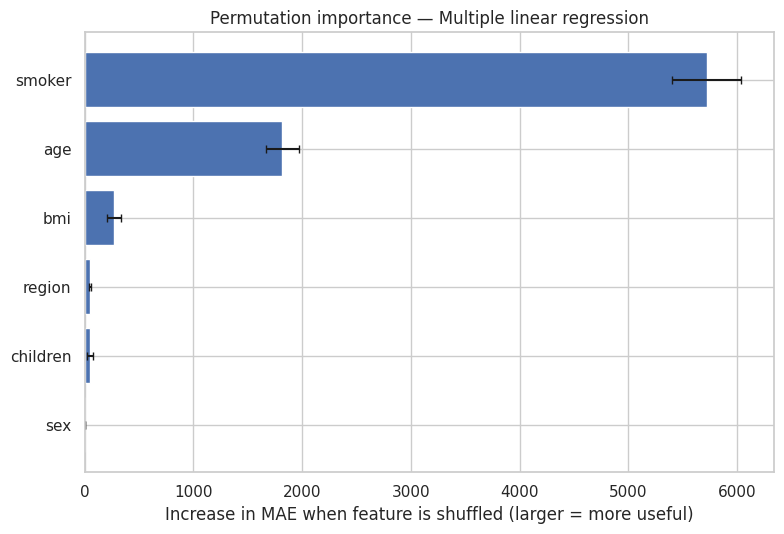

In [30]:
perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=15,
    random_state=SEED,
    n_jobs=-1,
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "mae_increase_mean": perm.importances_mean,
    "mae_increase_std": perm.importances_std,
}).sort_values("mae_increase_mean", ascending=False).reset_index(drop=True)
importance.to_csv(REPORT_DIR / "permutation_importance.csv", index=False)
display(importance.style.format({"mae_increase_mean": "{:,.2f}", "mae_increase_std": "{:,.2f}"}))

fig, ax = plt.subplots(figsize=(8, 5.5))
plot_importance = importance.sort_values("mae_increase_mean", ascending=True)
ax.barh(plot_importance["feature"], plot_importance["mae_increase_mean"],
        xerr=plot_importance["mae_increase_std"], capsize=3)
ax.set_title(f"Permutation importance — {best_model_name}")
ax.set_xlabel("Increase in MAE when feature is shuffled (larger = more useful)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "11_permutation_importance.png", dpi=160, bbox_inches="tight")
plt.show()

,grouping,grouping_value,n,mae,median_absolute_error,mean_signed_error,mean_actual_charges,mean_predicted_charges
0,smoker,no,214,"3,129.74","2,172.81",-386.19,"7,862.09","8,248.28"
1,smoker,yes,54,"8,348.08","7,992.73",442.36,"33,204.10","32,761.74"
2,age_band,18–29,87,"3,845.44","2,133.09",424.47,"7,487.29","7,062.83"
3,age_band,30–44,82,"4,145.34","3,502.50","-1,081.93","13,457.22","14,539.15"
4,age_band,45–59,75,"4,376.55","2,712.36",-334.46,"16,015.75","16,350.22"
5,age_band,60+,24,"4,910.33","3,182.46",754.90,"21,643.36","20,888.46"


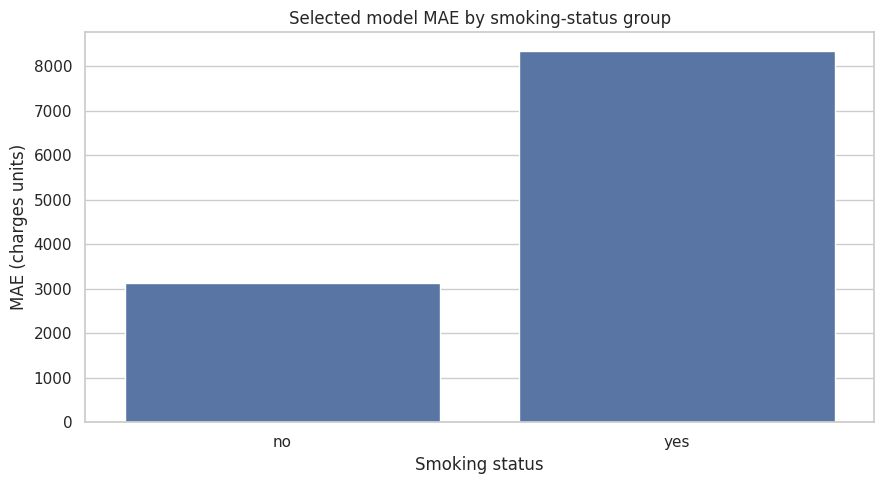

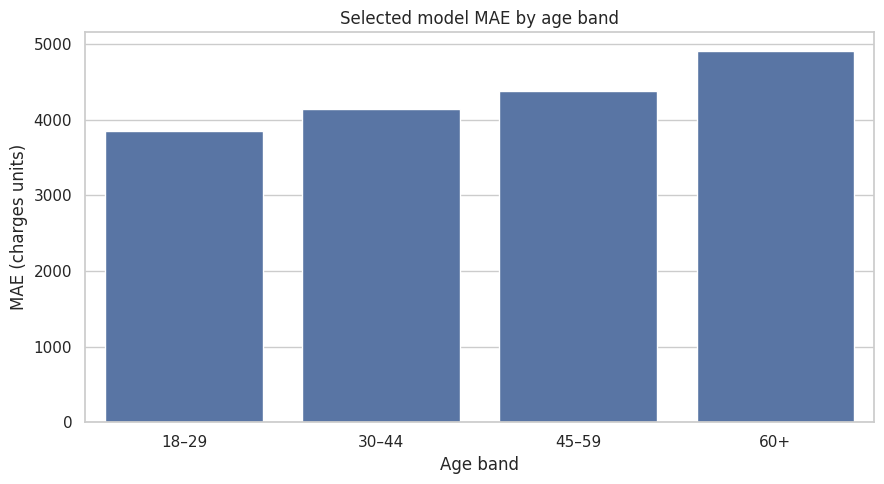

In [31]:
error_audit = X_test[["age", "smoker"]].copy()
error_audit["actual_charges"] = y_test
error_audit["predicted_charges"] = np.asarray(best_test_pred)
error_audit["residual_actual_minus_predicted"] = (
    error_audit["actual_charges"] - error_audit["predicted_charges"]
)
error_audit["absolute_error"] = error_audit["residual_actual_minus_predicted"].abs()
error_audit["age_band"] = pd.cut(
    error_audit["age"],
    bins=[0, 29, 44, 59, np.inf],
    labels=["18–29", "30–44", "45–59", "60+"],
    include_lowest=True,
)

subgroup_tables = []
for grouping in ["smoker", "age_band"]:
    grouped = error_audit.groupby(grouping, observed=False).agg(
        n=("absolute_error", "size"),
        mae=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_signed_error=("residual_actual_minus_predicted", "mean"),
        mean_actual_charges=("actual_charges", "mean"),
        mean_predicted_charges=("predicted_charges", "mean"),
    ).reset_index().rename(columns={grouping: "grouping_value"})
    grouped.insert(0, "grouping", grouping)
    subgroup_tables.append(grouped)

subgroup_results = pd.concat(subgroup_tables, ignore_index=True)
subgroup_results.to_csv(REPORT_DIR / "subgroup_error_audit.csv", index=False)
display(subgroup_results.style.format({
    "mae": "{:,.2f}", "median_absolute_error": "{:,.2f}",
    "mean_signed_error": "{:,.2f}", "mean_actual_charges": "{:,.2f}",
    "mean_predicted_charges": "{:,.2f}",
}))

fig, ax = plt.subplots(figsize=(9, 5))
smoker_errors = subgroup_results[subgroup_results["grouping"] == "smoker"]
sns.barplot(data=smoker_errors, x="grouping_value", y="mae", ax=ax, color=sns.color_palette()[0])
ax.set_title("Selected model MAE by smoking-status group")
ax.set_xlabel("Smoking status")
ax.set_ylabel("MAE (charges units)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "12_subgroup_mae_smoker.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
age_errors = subgroup_results[subgroup_results["grouping"] == "age_band"]
sns.barplot(data=age_errors, x="grouping_value", y="mae", ax=ax, color=sns.color_palette()[0])
ax.set_title("Selected model MAE by age band")
ax.set_xlabel("Age band")
ax.set_ylabel("MAE (charges units)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "13_subgroup_mae_age_band.png", dpi=160, bbox_inches="tight")
plt.show()

In [32]:
import joblib

joblib.dump(best_model, MODEL_DIR / "selected_regression_pipeline.joblib")
run_summary = {
    "dataset_file_name": DATA_SOURCE_NAME,
    "rows_used": int(len(df)),
    "features": FEATURES,
    "target": TARGET,
    "test_size": TEST_SIZE,
    "random_seed": SEED,
    "cross_validation_folds": N_SPLITS,
    "selection_metric": "mean 5-fold cross-validation MAE on training split",
    "selected_model": best_model_name,
    "selected_model_test_metrics": final_test_metrics,
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
}
with open(REPORT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_summary, f, indent=2)

print("Saved reports:")
for path in sorted(REPORT_DIR.glob("*")):
    if path.is_file():
        print(" -", path)
print("\nSaved figures:", len(list(FIGURE_DIR.glob("*.png"))))
print("Saved pipeline:", MODEL_DIR / "selected_regression_pipeline.joblib")

Saved reports:
 - reports/cross_validation_results.csv
 - reports/model_comparison.csv
 - reports/permutation_importance.csv
 - reports/run_summary.json
 - reports/subgroup_error_audit.csv

Saved figures: 13
Saved pipeline: models/selected_regression_pipeline.joblib
